# 🔗 Notebook 2 — Chain Growth & Molecular Weight Distributions
| | |
|---|---|
| ⏱ Time | ~40 min |
| 🧭 Type | **steady state Monte Carlo** (book Ch. 2–3): constant probabilities, chains built one after another |
| 🎯 You will learn | simulate chains one by one · the counting vector `D` · n-CLD, w-CLD and log-scale MWD · Nn, Nw, Đ · combination vs. transfer |
| 🧰 Uses | Trick #1 (`Rnd ≤ P`) and Trick #2 (count) from Notebook 1 |
| 📖 Book | Sec. 2.3 · Algorithms 3.1 and 3.2 |

The book (*Monte Carlo Methods in Polymer Reaction Engineering: From Mechanisms to Molecular Architecture*) explains where the probabilities come from. Here we **run** the algorithms and **look** at the results.

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt

if not hasattr(np, "trapezoid"):     # older NumPy versions call it trapz
    np.trapezoid = np.trapz

random.seed(1)

## 1 · One chain at a time
A polymer radical (living chain) keeps asking: *propagate, with the probability of propagation `P_p`, or terminate?* This is the function from Notebook 0:

In [2]:
def grow_chain(Pp):
    n = 1                              # a new chain has one unit
    while random.random() <= Pp:       # propagate?
        n += 1                         # add one monomer
    return n                           # the chain is now dead

In [3]:
for i in range(5):
    print(grow_chain(0.99))

41
620
143
49
40


## 2 · Many chains
The book recommends `N = 10⁵ – 10⁶` chains for smooth distributions. We make 100,000 and keep every length in a list.

In [4]:
N = 100_000
Pp = 0.99

lengths = []
for i in range(N):
    lengths.append(grow_chain(Pp))

### The counting vector `D`
The book stores the results as `D[n]` = number of chains with length `n` (Notebook 0, section 9). NumPy's `np.bincount` builds exactly that from the list of lengths:

In [5]:
D = np.bincount(lengths)

print(D[1], "chains of length 1")
print(D[100], "chains of length 100")

1027 chains of length 1
387 chains of length 100


### Averages: Nn, Nw and Đ
With `n` the chain length:
- number average `Nn = Σ n·D[n] / Σ D[n]`
- weight average `Nw = Σ n²·D[n] / Σ n·D[n]`
- dispersity `Đ = Nw / Nn`

`np.arange(len(D))` makes the array `0, 1, 2, …` with one `n` for every slot of `D`:

In [6]:
n = np.arange(len(D))

Nn = np.sum(n * D) / np.sum(D)
Nw = np.sum(n**2 * D) / np.sum(n * D)
print(f"Nn = {Nn:.1f}   Nw = {Nw:.1f}   Đ = {Nw / Nn:.3f}")

Nn = 100.2   Nw = 200.0   Đ = 1.997


Theory (the Flory distribution) predicts `Nn = 1/(1 − P_p)`, `Nw = (1 + P_p)/(1 − P_p)` and `Đ = 1 + P_p`:

In [7]:
print(f"Nn = {1/(1 - Pp):.1f}   Nw = {(1 + Pp)/(1 - Pp):.1f}   Đ = {1 + Pp:.3f}")

Nn = 100.0   Nw = 199.0   Đ = 1.990


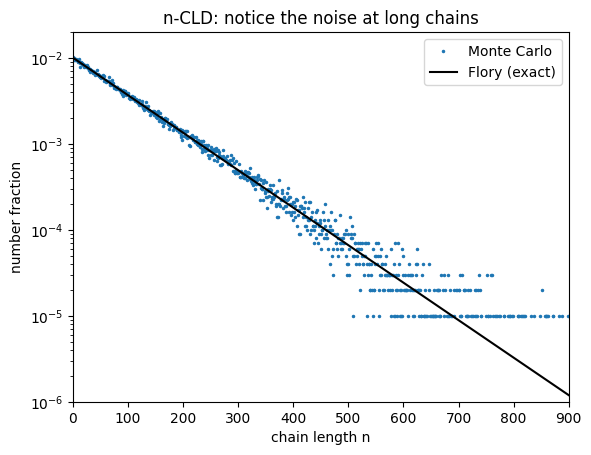

In [8]:
#@title Plot the number chain length distribution (n-CLD)
nn = np.arange(1, len(D))
plt.plot(nn, D[1:]/D.sum(), ".", ms=3, label="Monte Carlo")
plt.plot(nn, (1-Pp)*Pp**(nn-1), "k-", label="Flory (exact)")
plt.yscale("log"); plt.xlim(0, 900); plt.ylim(1e-6, 2e-2)
plt.xlabel("chain length n"); plt.ylabel("number fraction"); plt.legend()
plt.title("n-CLD: notice the noise at long chains"); plt.show()

## 3 · From counts to a log-scale MWD (book Sec. 2.3.1)
Raw counts are noisy for long chains. The book's recipe has four steps; we do them one at a time.

### Step 1 · Group the chains into bins of width `Δn`
For every bin, we keep the **number of chains** in it (`y`) and their **average length** (`x`).

In [9]:
dn = 5
x = []
y = []

for start in range(1, len(D), dn):
    chains_in_bin = D[start:start + dn]
    lengths_in_bin = n[start:start + dn]
    if chains_in_bin.sum() > 0:
        x.append(np.sum(lengths_in_bin * chains_in_bin) / chains_in_bin.sum())
        y.append(chains_in_bin.sum())

### Step 2 · Normalize: area under the curve = 1
The trapezoidal rule (`np.trapezoid`) gives the area; dividing by it makes the n-CLD a proper distribution `f`.

In [10]:
x = np.array(x)
y = np.array(y)

f = y / np.trapezoid(y, x)

### Step 3 · Number → weight distribution
Long chains carry more mass, so the weight distribution is `w = n · f`, normalized again.

In [11]:
w = x * f
w = w / np.trapezoid(w, x)

### Step 4 · Log scale, like a GPC trace
With the molecular weight `MW = n × MW_mer`, the log-scale distribution is `w_log = ln(10) · MW · w`, normalized over `log₁₀ MW`.

In [12]:
MW_mer = 104.15                  # styrene, g/mol
MW = x * MW_mer
logMW = np.log10(MW)

w_log = np.log(10) * MW * w
w_log = w_log / np.trapezoid(w_log, logMW)

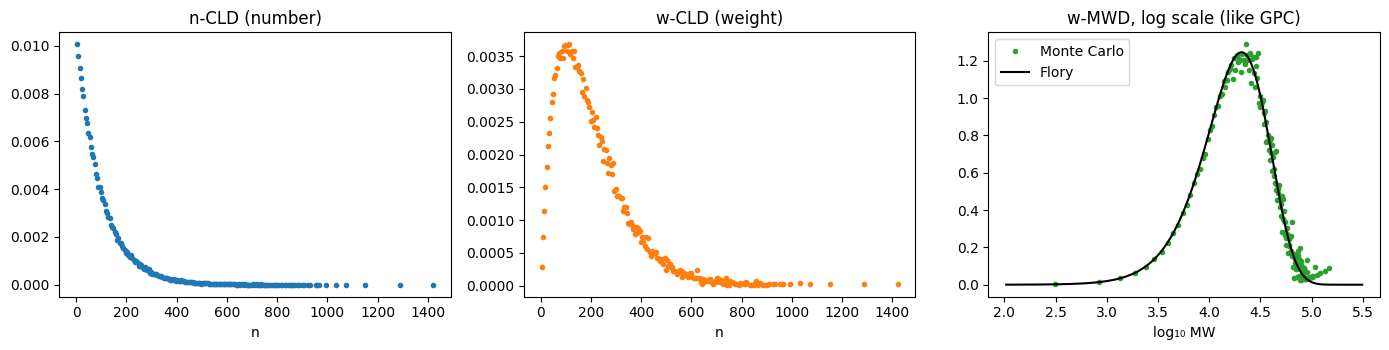

In [13]:
#@title Plot n-CLD, w-CLD and w-MWD
nf = np.arange(1, 3000); wf = nf*(1-Pp)**2*Pp**(nf-1)
wlog_f = np.log(10)*nf*wf; wlog_f /= np.trapezoid(wlog_f, np.log10(nf*MW_mer))
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].plot(x, f, "o", ms=3); ax[0].set_title("n-CLD (number)"); ax[0].set_xlabel("n")
ax[1].plot(x, w, "o", ms=3, c="tab:orange"); ax[1].set_title("w-CLD (weight)"); ax[1].set_xlabel("n")
ax[2].plot(logMW, w_log, "o", ms=3, c="tab:green", label="Monte Carlo")
ax[2].plot(np.log10(nf*MW_mer), wlog_f, "k-", label="Flory")
ax[2].set_title("w-MWD, log scale (like GPC)"); ax[2].set_xlabel("log₁₀ MW"); ax[2].legend()
plt.tight_layout(); plt.show()

### A second option: logarithmic bins
Equal-width bins become sparse and noisy at high MW on a log axis. Bins equally spaced in **log n** fix that. We'll use this helper for the plots from now on (it's in a collapsed cell because it's only plotting support).

In [14]:
#@title Helper: log-binned MWD (used for plots)
def log_binned_mwd(D, MW_mer=104.15, bins=50):
    n = np.arange(len(D))
    edges = np.logspace(0, np.log10(len(D)), bins)
    mass, _ = np.histogram(n, bins=edges, weights=n*D)
    xb = np.log10(np.sqrt(edges[1:]*edges[:-1]) * MW_mer)
    yb = mass / np.diff(np.log10(edges))
    return xb, yb / np.trapezoid(yb, xb)
print("helper ready")

helper ready


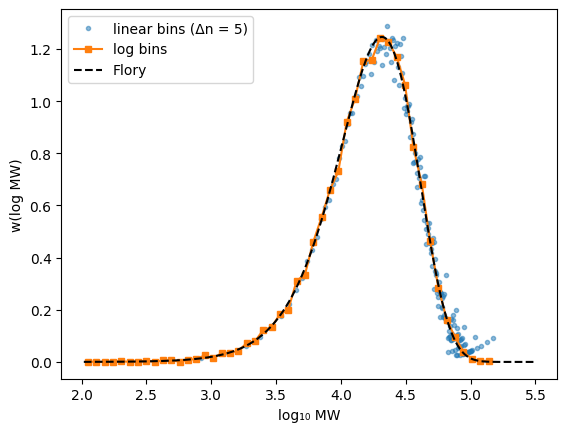

In [15]:
#@title Plot linear bins vs. log bins
xl, yl = log_binned_mwd(D)
plt.plot(logMW, w_log, "o", ms=3, alpha=0.5, label="linear bins (Δn = 5)")
plt.plot(xl, yl, "s-", ms=4, label="log bins")
plt.plot(np.log10(nf*MW_mer), wlog_f, "k--", label="Flory")
plt.xlabel("log₁₀ MW"); plt.ylabel("w(log MW)"); plt.legend(); plt.show()

## 4 · How many chains do I need?
Trick #2 again: noise falls like 1/√N. Make three populations of different size:

In [16]:
populations = {}

for N_try in [1_000, 10_000, 100_000]:
    chains = []
    for i in range(N_try):
        chains.append(grow_chain(Pp))
    populations[N_try] = np.bincount(chains)

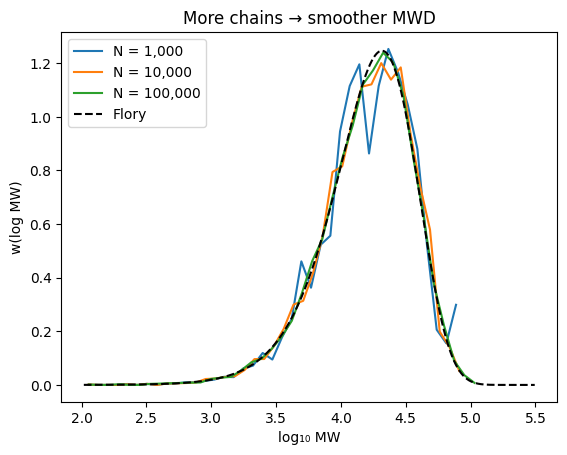

In [17]:
#@title Plot the MWD for each population size
for N_try in populations:
    lm, wl = log_binned_mwd(populations[N_try], bins=40)
    plt.plot(lm, wl, label=f"N = {N_try:,}")
plt.plot(np.log10(nf*MW_mer), wlog_f, "k--", label="Flory")
plt.xlabel("log₁₀ MW"); plt.ylabel("w(log MW)"); plt.legend(); plt.title("More chains → smoother MWD"); plt.show()

### 💡 A faster way (book Sec. 5.3, geometric sampling)
For this simple mechanism, chain lengths follow a *geometric* distribution, which NumPy can sample all at once. Loops are better for **learning** and for **complex mechanisms**; shortcuts like this are for **speed** when the maths is simple.

In [18]:
fast_lengths = np.random.geometric(1 - Pp, size=100_000)
print(f"Nn from the loop:      {np.mean(lengths):.1f}")
print(f"Nn from the shortcut:  {np.mean(fast_lengths):.1f}")

Nn from the loop:      100.2
Nn from the shortcut:  99.9


## 5 · Styrene: termination by combination vs. transfer (book Case Study 3.1)
When a chain stops, two things can happen:
- **transfer to monomer** (probability `1 − P_tc`): the chain is dead as it is → record `n`
- **combination** (probability `P_tc`): it couples with a *second* growing chain → record `n + m`

### Algorithm 3.1 (simple version)

In [19]:
def styrene_simple(N, Pp, Ptc):
    dead = []
    n_combined = 0
    for i in range(N):
        n = grow_chain(Pp)
        if random.random() <= Ptc:         # combination
            m = grow_chain(Pp)
            dead.append(n + m)
            n_combined += 1
        else:                              # transfer to monomer
            dead.append(n)
    return dead, n_combined

But wait: that second chain `m` was itself allowed to stop by **transfer**, not just combination.

### Algorithm 3.2 (corrected)
The partner chain must also decide how it ends. If it picks transfer, it becomes a dead chain **on its own**, and we grow another partner, until one ends by combination (*repeat … until*).

In [20]:
def generate_second_chain(Pp, Ptc, dead):
    while True:
        m = grow_chain(Pp)
        if random.random() <= Ptc:    # partner also combines
            return m
        dead.append(m)                # partner transferred: dead on its own

In [21]:
def styrene_corrected(N, Pp, Ptc):
    dead = []
    n_combined = 0
    for i in range(N):
        n = grow_chain(Pp)
        if random.random() <= Ptc:
            m = generate_second_chain(Pp, Ptc, dead)
            dead.append(n + m)
            n_combined += 1
        else:
            dead.append(n)
    return dead, n_combined

### Does it matter?
For `P_tc = 0.5`, a little bookkeeping (see the book) says that **1/3** of the dead chains should come from combination.

In [22]:
Ptc = 0.5
dead_A, comb_A = styrene_simple(100_000, Pp, Ptc)
dead_B, comb_B = styrene_corrected(100_000, Pp, Ptc)

In [23]:
print(f"simple:    {comb_A / len(dead_A):.3f} of dead chains from combination")
print(f"corrected: {comb_B / len(dead_B):.3f} of dead chains from combination")
print(f"theory:    {(Ptc/2) / (Ptc/2 + 1 - Ptc):.3f}")

simple:    0.500 of dead chains from combination
corrected: 0.333 of dead chains from combination
theory:    0.333


The simple version gets it wrong; the corrected one matches theory. **Small details in an algorithm change the answer**, so always check against a known result.

### The classic result: Đ ≈ 2 for transfer, Đ ≈ 1.5 for pure combination

In [24]:
results = {}
for Ptc in [0.0, 0.5, 1.0]:
    dead, n_combined = styrene_corrected(100_000, Pp, Ptc)
    results[Ptc] = np.bincount(dead)

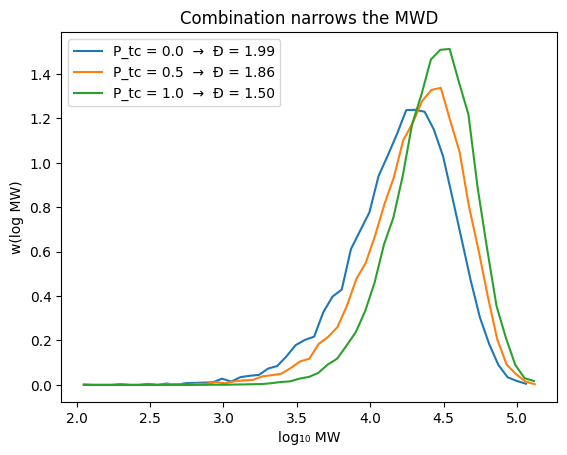

In [25]:
#@title Plot the MWD for each P_tc
for Ptc in results:
    Dv = results[Ptc]; nv = np.arange(len(Dv))
    PDI = np.sum(nv**2*Dv)*np.sum(Dv)/np.sum(nv*Dv)**2
    lm, wl = log_binned_mwd(Dv)
    plt.plot(lm, wl, label=f"P_tc = {Ptc}  →  Đ = {PDI:.2f}")
plt.xlabel("log₁₀ MW"); plt.ylabel("w(log MW)"); plt.legend(); plt.title("Combination narrows the MWD"); plt.show()

## ✅ Recap
- One `while Rnd ≤ P_p` loop = one chain. Repeat → distribution.
- The counting vector `D` and the book's four post-processing steps turn counts into a GPC-like curve.
- A missing check in an algorithm (the partner chain's termination) changes the result; validate!

### 🧪 Try it yourself
1. Change `Pp` to 0.999. How does Nn change? (Expect 1/(1 − P_p).)
2. Try `dn = 1` and `dn = 50` in Step 1. When is the bin too coarse? Too fine?
3. Use `MW_mer = 100.12` (MMA) instead of styrene.

➡️ **Next: Notebook 3 — Copolymers & composition** (the full styrene case study with the book's parameters is Notebook 8)